<a href="https://colab.research.google.com/github/pdf1802/f1-data-science/blob/main/notebooks/race_simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏁 Tool 3 — Monte Carlo Race Simulator
**Code:** `tools/race_simulator.py` (grid, summaries) on top of `tools/race_engine.py` (the lap-by-lap engine) ·
**Depends on:** Module 1 (lap time), Module 2 (overtakes), circuit profiles

**Question:** given the grid and everybody's strategy, how does the race play out — and how sure can we be?

One simulated race is one possible outcome. A thousand of them, each with its own random draws (starts, pace on the
day, Safety Cars, overtake rolls), give a **distribution**: P(win), P(podium), expected position.

> **V3.1 (Nov 2026) — one implementation, explained here.** The code of this tool now lives in
> [`tools/race_simulator.py`](../tools/race_simulator.py), shared by the dashboard, the Race Engineer and the tests. This notebook walks
> through it step by step: each step shows the **real source** (`show(...)`) and runs it on real races
> from `data/laps_2022_2025.parquet` with the V3.1 models. The earlier self-contained version (V2 models,
> its own copy of the code) is in the git history. The engine itself is `tools/race_engine.py`, also used by the What-If tool, the backtest and the Race Engineer.

In [1]:
# Setup — local checkout or Colab. Data and models are not in git (see the README: Data, Train the models).
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:                       # Colab: clone the repo, models + Parquet from Drive
    if not os.path.exists("/content/f1-data-science"):
        subprocess.run(["git", "clone", "-q", "https://github.com/pdf1802/f1-data-science", "/content/f1-data-science"], check=True)
    os.chdir("/content/f1-data-science")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("F1_MODEL_DIR", "/content/drive/MyDrive/f1_models")
    os.environ.setdefault("F1_LAPS", "/content/drive/MyDrive/f1_data/laps_2022_2025.parquet")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, display
from tools import shared, training

def show(obj):
    """Display the real source of a function / class from tools/ — the code the dashboard runs."""
    return Code(inspect.getsource(obj), language="python")

LAPS_ALL = pd.read_parquet(os.environ.get("F1_LAPS", os.path.join(ROOT, "data", "laps_2022_2025.parquet")))
LAPS, WET = training.dry_races(LAPS_ALL)
print(f"Models: {os.path.relpath(shared.resolve_model_dir(), ROOT)}/")
print(f"Laps: {LAPS_ALL.groupby(['Season', 'Race']).ngroups} races, {len(LAPS_ALL):,} laps "
      f"· {LAPS.groupby(['Season', 'Race']).ngroups} dry races used")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})

Models: models/
Laps: 43 races, 44,526 laps · 36 dry races used


In [2]:
# FastF1 for qualifying sessions: offline, from the cache (cache_drive/f1_cache or $F1_CACHE_DIR).
# F1 live timing answers 401 to downloads since Oct 2026, so only cached sessions load.
import fastf1
fastf1.set_log_level("ERROR")
CACHE = shared.enable_fastf1_cache()
print(f"FastF1 offline · cache with {len([p for p in os.scandir(CACHE) if p.is_dir()])} seasons")

FastF1 offline · cache with 4 seasons


## Step 1 — The grid, from qualifying

V2 derived team pace factors from the first five races of the season (downloaded from FastF1). V3.1 reads pace from
the **qualifying gaps of the same weekend**: `PaceFactor = 1 + spread × (QualyTime / pole − 1)`. Same idea (*fastest
car = 1.000*), but it uses this weekend's cars, not a season average, and needs no extra downloads.

In [3]:
from tools import qualy_predictor as qp, race_simulator as rs
from tools.race_engine import actual_result
show(rs.grid_from_qualifying)

def grid_from_qualifying(quali: pd.DataFrame, total_laps: int,
                         start_compound: str = "MEDIUM", next_compound: str = "HARD",
                         pit_lap: int | None = None, pace_spread: float = 1.0) -> pd.DataFrame:
    """
    Editable strategy grid from a qualifying table (Driver, Team, QualyTime, QualyRank).
    PaceFactor = 1 + spread × (QualyTime / pole − 1): qualifying gaps as race pace.
    """
    q = quali.sort_values("QualyRank").reset_index(drop=True)
    pole = q["QualyTime"].min()
    pit_lap = pit_lap or int(round(total_laps * 0.45))
    return pd.DataFrame({
        "Driver": q["Driver"], "Team": q["Team"], "Grid": q["QualyRank"].astype(int),
        "PaceFactor": (1 + pace_spread * (q["QualyTime"] / pole - 1)).round(4),
        "StartCompound": start_compound, "StartAge": 1,
        "Stop1Lap": pit_lap, "Stop1Compound": next_compound,
        "Stop2Lap": 0, "Stop2Compound": next_compound,
    })[GRID_COLUMNS]

## Step 2 — Everybody's real strategy

To check the engine against a real race we give every driver the strategy **they really ran** (start compound and
tyre age, the first two stops) — `rs.with_real_strategies`. Then the only thing the simulator has to get right is
the race itself: pace, tyres, stops, traffic, overtakes.

In [4]:
SEASON, RACE = 2023, "Bahrain Grand Prix"
r = LAPS[(LAPS.Season == SEASON) & (LAPS.Race == RACE)]
L = int(r.TotalLaps.iloc[0])
quali = qp.load_qualifying_results(SEASON, RACE)
grid = rs.with_real_strategies(rs.grid_from_qualifying(quali, L), LAPS, SEASON, RACE)
print("Grid check:", rs.validate_grid(grid, L) or "OK")
grid.head(10)

Grid check: ['PIA: dry races require two different compounds (rule, not optional).']


,Driver,Team,Grid,PaceFactor,StartCompound,StartAge,Stop1Lap,Stop1Compound,Stop2Lap,Stop2Compound
0,VER,Red Bull Racing,1,1.0000,SOFT,4,14,SOFT,36,HARD
1,PER,Red Bull Racing,2,1.0015,SOFT,4,17,SOFT,34,HARD
2,LEC,Ferrari,3,1.0033,SOFT,1,13,HARD,33,HARD
3,SAI,Ferrari,4,1.0050,SOFT,4,13,HARD,31,HARD
4,ALO,Aston Martin,5,1.0070,SOFT,4,14,HARD,34,HARD
5,RUS,Mercedes,6,1.0070,SOFT,4,13,HARD,31,HARD
6,HAM,Mercedes,7,1.0075,SOFT,4,12,HARD,30,HARD
7,HUL,Haas F1 Team,8,1.0123,SOFT,4,11,HARD,26,HARD
8,STR,Aston Martin,9,1.0126,SOFT,4,15,HARD,30,HARD
9,OCO,Alpine,10,1.0134,SOFT,4,12,HARD,15,HARD


## Step 3 — The engine: what V2 got wrong

The V2 notebook had a `DriverState` dataclass and a lap loop. It ran, it gave probabilities — and three design flaws
made those probabilities say much less than they seemed to. Finding them is the best lesson in this tool:

1. **Overtakes were cosmetic.** A successful Module 2 roll swapped `position`, but the final classification sorted by
   `race_time` — so the swap was thrown away and track position never mattered.
   → Now a faster car that catches the car ahead is **held up** (its lap time is clamped to the car ahead + a minimum
   gap) unless it wins the Module 2 roll. Failing to pass costs real time.
2. **The Safety Car added +30 s to everyone.** Adding a constant to every car changes nothing.
   → Now an SC **bunches** the field, makes stops cheap, and cars whose planned stop is close box under it.
3. **Too deterministic once 1 and 2 were fixed.** Independent per-lap noise averages out over 50 laps
   (σ·√50 ≈ 1 s). Real race-to-race variance is *correlated*: a driver's pace on the day, the start.
   → `RACE_FORM_STD` (per driver, per race) and `START_STD` (launch).

And it is **vectorised**: the tyre state only depends on (compound, tyre age, lap), so Module 1 fills a lookup table
once and the race is numpy on arrays of shape (simulations × drivers). One lap of every simulated race:

In [5]:
from tools import race_engine as eng
show(eng.step)

def step(state: dict, setup: dict, cfg: dict, dr: Draws, li: int) -> dict:
    """
    Advance every simulation by one lap (in place). `li` indexes the lap inside
    the Draws arrays. Returns per-lap events for the live view.
    """
    lap = state["lap"] + 1
    L, D = setup["L"], setup["D"]
    S = state["cum"].shape[0]
    sims, drv = np.arange(S)[:, None], np.arange(D)[None, :]
    base = cfg.get("base_laptime", BASE_LAPTIME)
    circuit_enc = encode_circuit(cfg.get("circuit"))
    cum, comp, age, nxt, retired = (state["cum"], state["comp"], state["age"],
                                    state["nxt"], state["retired"])

    # --- Safety Car
    deploy = (state["sc_left"] == 0) & (dr.sc_u[:, li] < cfg["sc_prob_per_lap"]) & (lap > 1) & (lap < L - 1)
    state["sc_left"] = np.where(deploy, dr.sc_len[:, li], state["sc_left"])
    state["sc_count"] += deploy
    sc = state["sc_left"] > 0

    # --- Pit decisions (planned, or opportunistic under SC)
    k = np.minimum(nxt, MAX_STOPS - 1)
    planned = np.where(nxt >= MAX_STOPS, NO_STOP, state["stop_laps"][sims, drv, k])
    has_stop = planned < NO_STOP
    pit = has_stop & (planned == lap)
    if cfg.get("sc_pit_window", 0) > 0:
        pit |= has_stop & sc[:, None] & (planned - lap <= cfg["sc_pit_window"]) & (planned > lap)
    pit &= ~retired
    new_comp = state["stop_comp"][sims, drv, k]

    # --- Lap times
    delta = setup["table"][setup["team_idx"][None, :], comp, np.minimum(age, setup["max_age"]), lap]
    racing = lap_time_from_delta(delta, setup["pace"][None, :], base) + dr.form + dr.lap_noise[:, li]
    if not setup.get("fuel_in_model", True):           # V3 deltas are fuel-free: add it back (same for all)
        racing = racing + cfg.get("fuel_s_per_lap", FUEL_S_PER_LAP) * (L - lap)
    sc_time = base * SC_LAP_FACTOR + 0.1 * dr.lap_noise[:, li]
    lt = np.where(sc[:, None], sc_time, racing)
    pit_loss = cfg.get("pit_loss", PIT_COST_GREEN)
    pit_cost = np.where(sc, pit_loss * SC_PIT_RATIO, pit_loss)[:, None] + dr.pit_noise[:, li]
    lt = lt + np.where(pit, pit_cost, 0.0)

    # --- Running order at the start of the lap
    order = np.argsort(np.where(retired, BIG, cum), axis=1)
    cum_o = np.take_along_axis(cum, order, 1)
    gap_prev = np.diff(cum_o, axis=1, prepend=cum_o[:, :1])         # gap to car ahead (0 for leader)
    lt_o = np.take_along_axis(lt, order, 1)
    close = (np.arange(D)[None, :] > 0) & (gap_prev < DRS_WINDOW) & ~sc[:, None]
    lt_o = lt_o + np.where(close, DIRTY_AIR_PENALTY, 0.0)

    # Module 2 — one call for every in-range pair in every simulation
    comp_o, age_o = np.take_along_axis(comp, order, 1), np.take_along_axis(age, order, 1)
    prob = np.zeros((S, D))
    if close.any():
        si, pi = np.nonzero(close)
        prob[si, pi] = predict_overtake_probability(
            gap_prev[si, pi], comp_o[si, pi], comp_o[si, pi - 1], age_o[si, pi],
            age_o[si, pi - 1], np.full(len(si), lap), pi + 1, circuit=circuit_enc)

    # sequential pass down the order: held up unless the pass succeeds
    cand = cum_o + lt_o
    pit_o = np.take_along_axis(pit, order, 1)
    ret_o = np.take_along_axis(retired, order, 1)
    new = cand.copy()
    passed_o = np.zeros((S, D), dtype=bool)
    front = np.where(pit_o[:, 0] | ret_o[:, 0], -BIG, cand[:, 0])
    for i in range(1, D):
        c = cand[:, i]
        active = ~ret_o[:, i] & ~pit_o[:, i]
        blocked = active & (c < front + MIN_FOLLOW_GAP)
        passed = blocked & ~sc & (gap_prev[:, i] < DRS_WINDOW) & (dr.ovt_u[:, li, i] < prob[:, i])
        passed_o[:, i] = passed
        state["overtakes"] += passed
        new[:, i] = np.where(blocked & ~passed, front + MIN_FOLLOW_GAP, c)
        front = np.where(active, np.maximum(front, new[:, i]), front)

    # --- Safety Car bunching (after the lap, in the NEW order)
    if sc.any():
        o2 = np.argsort(np.where(ret_o, BIG, new), axis=1)
        n2 = np.take_along_axis(new, o2, 1)
        r2 = np.take_along_axis(ret_o, o2, 1)
  

## Step 4 — 1,000 races of Bahrain 2023

In [6]:
cfg = {"circuit": RACE, "track_temp": float(r.TrackTemp.mean()), "air_temp": float(r.AirTemp.mean())}
res = rs.simulate(grid, cfg, n_sims=1000, seed=1)
summary = res["summary"]
summary["Actual"] = summary.Driver.map(actual_result(LAPS, SEASON, RACE))
summary.round(2).head(12)

,Driver,Team,Grid,Win %,Podium %,Points %,Exp. position,Exp. points,DNF %,Avg stops,Median pos,Actual
0,VER,Red Bull Racing,1,45.9,88.4,98.1,2.31,19.66,1.9,1.98,2.0,1.0
1,LEC,Ferrari,3,21.5,73.9,97.9,3.05,16.57,1.9,1.99,3.0,NaN
2,PER,Red Bull Racing,2,23.3,68.6,96.7,3.34,16.26,3.1,1.97,3.0,2.0
3,SAI,Ferrari,4,6.4,39.0,97.9,4.29,12.68,1.9,1.98,4.0,4.0
4,RUS,Mercedes,6,1.0,10.2,98.1,5.77,9.03,1.9,1.98,6.0,7.0
5,ALO,Aston Martin,5,0.3,8.3,97.6,6.00,8.58,2.2,1.99,6.0,3.0
6,HAM,Mercedes,7,1.5,10.7,96.8,6.01,8.76,2.9,1.98,6.0,5.0
7,HUL,Haas F1 Team,8,0.1,0.8,94.2,8.30,3.96,1.8,1.99,8.0,15.0
8,STR,Aston Martin,9,0.0,0.1,90.0,8.83,3.14,2.0,1.99,9.0,6.0
9,OCO,Alpine,10,0.0,0.0,61.3,10.64,1.17,3.3,1.99,10.0,NaN


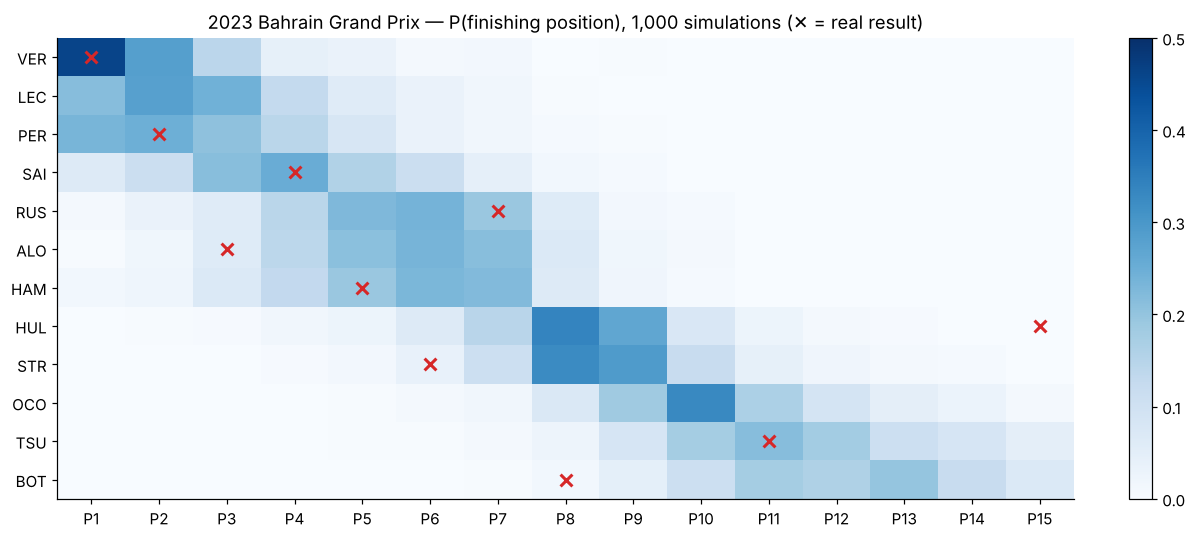

In [7]:
dist = rs.position_distribution(res, res["grid"])
top = summary.Driver.head(12).tolist()
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(dist.loc[top].values[:, :15], cmap="Blues", aspect="auto", vmin=0, vmax=0.5)
ax.set_yticks(range(len(top)), top); ax.set_xticks(range(15), [f"P{k}" for k in range(1, 16)])
act = summary.set_index("Driver").Actual
for i, d in enumerate(top):
    if pd.notna(act.get(d)) and act[d] <= 15:
        ax.scatter(act[d] - 1, i, marker="x", color="#d62728", s=60, linewidths=2)
ax.set_title(f"{SEASON} {RACE} — P(finishing position), 1,000 simulations (✕ = real result)")
plt.colorbar(im, ax=ax, fraction=0.025); ax.grid(False); plt.tight_layout(); plt.show()

## Validation — does simulating the race beat the grid order?

Same check for every dry race with a cached qualifying session: real grid order and real strategies in, 300
simulated races each, the expected finishing order out. We compare it with the real result (Spearman ρ, finishers
only) against the simplest baseline, **"they finish where they started"**, and check the uncertainty: how often is
the real position inside the simulated 10–90 % range?

(This is harder than the backtest in the README, which starts from the real state at 40 % distance.)

In [8]:
from scipy.stats import spearmanr
rows = []
for (season, race), rr in LAPS.groupby(["Season", "Race"]):
    try:
        q = qp.load_qualifying_results(int(season), race)
    except Exception:
        continue                                                   # qualifying not in the cache
    Lr = int(rr.TotalLaps.iloc[0])
    g = rs.with_real_strategies(rs.grid_from_qualifying(q, Lr), LAPS, int(season), race)
    sim = rs.simulate(g, {"circuit": race, "track_temp": float(rr.TrackTemp.mean()),
                          "air_temp": float(rr.AirTemp.mean())}, n_sims=300, seed=1)
    act = actual_result(LAPS, int(season), race)
    s = sim["summary"].set_index("Driver").join(act.rename("Actual"), how="inner")
    pos = pd.DataFrame(sim["positions"], columns=sim["grid"].Driver)
    lo, hi = pos.quantile(0.1), pos.quantile(0.9)
    inside = [(lo[d] <= s.Actual[d] <= hi[d]) for d in s.index]
    rows.append({"race": f"{season} {race.replace(' Grand Prix', '')}", "n": len(s),
                 "rho_engine": spearmanr(s["Exp. position"], s.Actual)[0],
                 "rho_grid": spearmanr(s.Grid, s.Actual)[0], "in_10_90": np.mean(inside)})
val = pd.DataFrame(rows).set_index("race")
print(f"{len(val)} races · mean ρ engine {val.rho_engine.mean():.3f} vs grid order {val.rho_grid.mean():.3f} · "
      f"engine better in {(val.rho_engine > val.rho_grid).sum()}/{len(val)} · "
      f"real position inside the 10–90 % range {val.in_10_90.mean():.0%}")
val.round(3).sort_values("rho_engine")

20 races · mean ρ engine 0.875 vs grid order 0.862 · engine better in 14/20 · real position inside the 10–90 % range 80%


,n,rho_engine,rho_grid,in_10_90
race,,,,
2024 Abu Dhabi,17,0.703,0.608,0.765
2025 Abu Dhabi,20,0.737,0.767,0.750
2025 Bahrain,19,0.767,0.781,0.526
2024 Monaco,16,0.797,0.976,0.812
2023 Bahrain,17,0.807,0.730,0.588
2025 Austrian,16,0.850,0.794,0.875
2024 Australian,17,0.865,0.865,0.882
2025 Monaco,18,0.880,0.874,0.778
2024 Miami,19,0.891,0.818,0.842


**What the numbers say.**

- **Bahrain 2023:** VER is the favourite (≈ 46 % to win, P1 for real) and the Red Bull / Ferrari / Mercedes order is
  right; the misses are the race-pace stories qualifying can't show — ALO expected ~6th, finished 3rd; STR ~9th → 6th;
  HUL ~8th → 15th. (LEC's NaN: he retired.)
- **20 races:** simulating the race with the real strategies beats the grid order on average (ρ **0.875 vs 0.862**)
  and in 14 of 20 races. A small edge — qualifying order is a strong baseline — but a real one.
- **The uncertainty is honest:** the real position falls inside the simulated 10–90 % range **80 %** of the time —
  exactly what an 80 % interval should do. (`RACE_FORM_STD` was tuned for this in the backtest; here it holds on
  a different question.)
- **Where it loses:** Monaco 2024 (0.80 vs 0.98). The real race was a procession: a lap-1 red flag gave everyone a
  free tyre change and nobody could pass. The engine still simulates stops, traffic and overtakes — a circuit where
  "the order stays the same" is the right model.

## Known limitations

- **Pace = qualifying gaps.** A car that is better in the race than over one lap (Aston Martin 2023) is invisible
  until it races — the Race Engineer fixes that by measuring pace from the laps already run.
- **Rivals' strategies are given, not decided.** Here they are the real ones; in the dashboard they are whatever you
  type. The engine does not optimise strategy for 20 teams at once.
- **Only two stops per driver** in the grid table; DNFs are random (≈ 2 % per car per race), not reliability data.
- The engine's tyre model has the biases of Module 1 (one-stop bias at abrasive circuits, MEDIUM ≈ HARD).